In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('incidents_2010_present.csv')

/tmp/ipykernel_23472/1787650778.py:4: DtypeWarning: Columns (62: DEPTH_OF_COVER, 64: BRIDGE_CROSSING_IND, 65: BRIDGE_TYPE, 66: RAILROAD_CROSSING_IND, 67: RAILROAD_TYPE, 68: ROAD_CROSSING_IND, 69: ROAD_TYPE, 73: WATER_DEPTH, 75: OFF_WATER_DEPTH, 77: OFFSHORE_STATE_ABBREVIATION, 78: OFF_INSTATE_AREA, 79: OFF_INSTATE_BLOCK, 80: OFFSHORE_COUNTY_NAME, 82: OFF_OCS_BLOCK, 90: PIPE_WALL_THICKNESS, 91: PIPE_SMYS, 103: VALVE_MAINLINE_DETAILS, 105: VALVE_MANUFACTURE_YEAR, 118: RUPTURE_DETAILS, 138: DRINKING_WATER_CONTAM_IND, 139: PRIVATE_WELL_CONTAM_IND, 140: PUBLIC_WATER_CONTAM_IND, 172: LENGTH_SEGMENT_ISOLATED, 182: EXCESSIVE_DEBRIS_IND, 183: LOW_OP_PRESSURE_IND, 184: LOW_FLOW_IND, 185: INCOMPAT_COMMOD_IND, 210: INVEST_FATIGUE_IND, 212: INVEST_INCORRECT_CONTROL_IND, 226: VISUAL_EXAM_DETAILS, 228: ATMOSPHERE_CORROSION_IND, 229: STRAY_CURRENT_CORROSION_IND, 240: CATHODIC_PRO_START_YEAR, 245: OTHER_CP_SURVEY_IND, 249: EXTERNALLY_COATED, 253: INT_CORROSIVE_COMMODITY_IND, 264: INT_ELBOW_LOC_IND, 271

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3255 entries, 0 to 3254
Columns: 588 entries, REPORT_RECEIVED_DATE to NARRATIVE
dtypes: float64(156), int64(5), object(15), str(412)
memory usage: 21.0+ MB


In [ ]:
df.shape

(3255, 588)

In [32]:
cause_columns = [
    'ON_OFF_SHORE',
    'LOCATION_TYPE',
    'INCIDENT_AREA_TYPE',
    'INCIDENT_AREA_SUBTYPE',
    'PIPE_FACILITY_TYPE',
    'SYSTEM_PART_INVOLVED',
    'SYSTEM_SUBPART_INVOLVED',
    'ITEM_INVOLVED',
    'PIPE_TYPE',
    'PIPE_DIAMETER',
    'PIPE_WALL_THICKNESS',
    'PIPE_SMYS',
    'PIPE_SPECIFICATION',
    'PIPE_SEAM_TYPE',
    'PIPE_COATING_TYPE',
    'MATERIAL_INVOLVED',
    'RELEASE_TYPE',
    'PUNCTURE_AXIAL',
    'PUNCTURE_CIRCUM',
    'LEAK_TYPE',
    'RUPTURE_ORIENT',
    'ACCIDENT_PSIG',
    'MOP_PSIG',
    'ACCIDENT_PRESSURE',
    'OPERATION_COMPLICATIONS_IND',
    'EXCESSIVE_DEBRIS_IND',
    'LOW_OP_PRESSURE_IND',
    'LOW_FLOW_IND',
    'INCOMPAT_COMMOD_IND',
    'OTHER_COMPLICATIONS_IND',
    'INTERNAL_INSPECTION_IND',
    'OTHER_INSPECTION_IND',
    'INSPECT_COMP_DETAILS'
]

new_df = df[cause_columns].copy()
new_df.head()

,ON_OFF_SHORE,LOCATION_TYPE,INCIDENT_AREA_TYPE,INCIDENT_AREA_SUBTYPE,PIPE_FACILITY_TYPE,SYSTEM_PART_INVOLVED,SYSTEM_SUBPART_INVOLVED,ITEM_INVOLVED,PIPE_TYPE,PIPE_DIAMETER,...,ACCIDENT_PRESSURE,OPERATION_COMPLICATIONS_IND,EXCESSIVE_DEBRIS_IND,LOW_OP_PRESSURE_IND,LOW_FLOW_IND,INCOMPAT_COMMOD_IND,OTHER_COMPLICATIONS_IND,INTERNAL_INSPECTION_IND,OTHER_INSPECTION_IND,INSPECT_COMP_DETAILS
0,ONSHORE,TOTALLY CONTAINED ON OPERATOR-CONTROLLED PROPERTY,ABOVEGROUND,TYPICAL ABOVEGROUND FACILITY PIPING OR APPURTE...,INTERSTATE,ONSHORE PUMP/METER STATION EQUIPMENT AND PIPING,NaN,PUMP,NaN,NaN,...,PRESSURE DID NOT EXCEED MOP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ONSHORE,TOTALLY CONTAINED ON OPERATOR-CONTROLLED PROPERTY,ABOVEGROUND,TYPICAL ABOVEGROUND FACILITY PIPING OR APPURTE...,INTERSTATE,ONSHORE TERMINAL/TANK FARM EQUIPMENT AND PIPING,NaN,INSTRUMENTATION,NaN,NaN,...,PRESSURE DID NOT EXCEED MOP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ONSHORE,TOTALLY CONTAINED ON OPERATOR-CONTROLLED PROPERTY,ABOVEGROUND,TYPICAL ABOVEGROUND FACILITY PIPING OR APPURTE...,INTRASTATE,ONSHORE TERMINAL/TANK FARM EQUIPMENT AND PIPING,NaN,SUMP/SEPARATOR,NaN,NaN,...,PRESSURE DID NOT EXCEED MOP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ONSHORE,TOTALLY CONTAINED ON OPERATOR-CONTROLLED PROPERTY,"TANK, INCLUDING ATTACHED APPURTENANCES",NaN,INTRASTATE,"ONSHORE BREAKOUT TANK OR STORAGE VESSEL, INCLU...",ATMOSPHERIC OR LOW PRESSURE,OTHER,NaN,NaN,...,PRESSURE DID NOT EXCEED MOP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ONSHORE,TOTALLY CONTAINED ON OPERATOR-CONTROLLED PROPERTY,ABOVEGROUND,TYPICAL ABOVEGROUND FACILITY PIPING OR APPURTE...,INTERSTATE,ONSHORE TERMINAL/TANK FARM EQUIPMENT AND PIPING,NaN,FLANGE,NaN,NaN,...,PRESSURE EXCEEDED 110% OF MOP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
#get dataset with most non-na values
#new_df = new_df[]
null_counts = new_df.isnull().sum()
new_df = new_df[null_counts[null_counts<1000].index]
new_df.shape

(3255, 12)

In [84]:
new_df.info()
#ONSHORE is 1 and OFFSHORE is 0
#PIPE_FACILITY_TYPE (INTERSTATE is 0 and INTRASTATE is 1)
#MATERIAL_INVOLVED: (CARBON STEEL is 1 and other is 0)
#ACCIDENT_PRESSURE: Pressure did not exceed MOP: 0, Pressure exceeded MOP but not 110%
#:1, pressure exceeded 110%:2

<class 'pandas.DataFrame'>
Index: 3235 entries, 0 to 3254
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ON_OFF_SHORE          3235 non-null   int64  
 1   LOCATION_TYPE         3235 non-null   str    
 2   INCIDENT_AREA_TYPE    3235 non-null   str    
 3   PIPE_FACILITY_TYPE    3235 non-null   str    
 4   SYSTEM_PART_INVOLVED  3235 non-null   str    
 5   ITEM_INVOLVED         3235 non-null   str    
 6   MATERIAL_INVOLVED     3235 non-null   float64
 7   RELEASE_TYPE          3235 non-null   str    
 8   LEAK_TYPE             3235 non-null   str    
 9   ACCIDENT_PSIG         3235 non-null   float64
 10  MOP_PSIG              3235 non-null   float64
 11  ACCIDENT_PRESSURE     3235 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 773.4 KB


Most frequent value for each feature:


,feature,most_frequent_value,frequency,frequency_percent
0,ON_OFF_SHORE,1,3235,100.00
1,RELEASE_TYPE,LEAK,2497,77.19
2,ACCIDENT_PRESSURE,0.0,2426,74.99
3,LOCATION_TYPE,TOTALLY CONTAINED ON OPERATOR-CONTROLLED PROPERTY,2307,71.31
4,PIPE_FACILITY_TYPE,INTERSTATE,2104,65.04
5,MATERIAL_INVOLVED,0.0,2003,61.92
6,INCIDENT_AREA_TYPE,ABOVEGROUND,1725,53.32
7,LEAK_TYPE,OTHER,1114,34.44
8,SYSTEM_PART_INVOLVED,ONSHORE PUMP/METER STATION EQUIPMENT AND PIPING,1088,33.63
9,ITEM_INVOLVED,PIPE,834,25.78


Exported to most_frequent_by_feature.csv


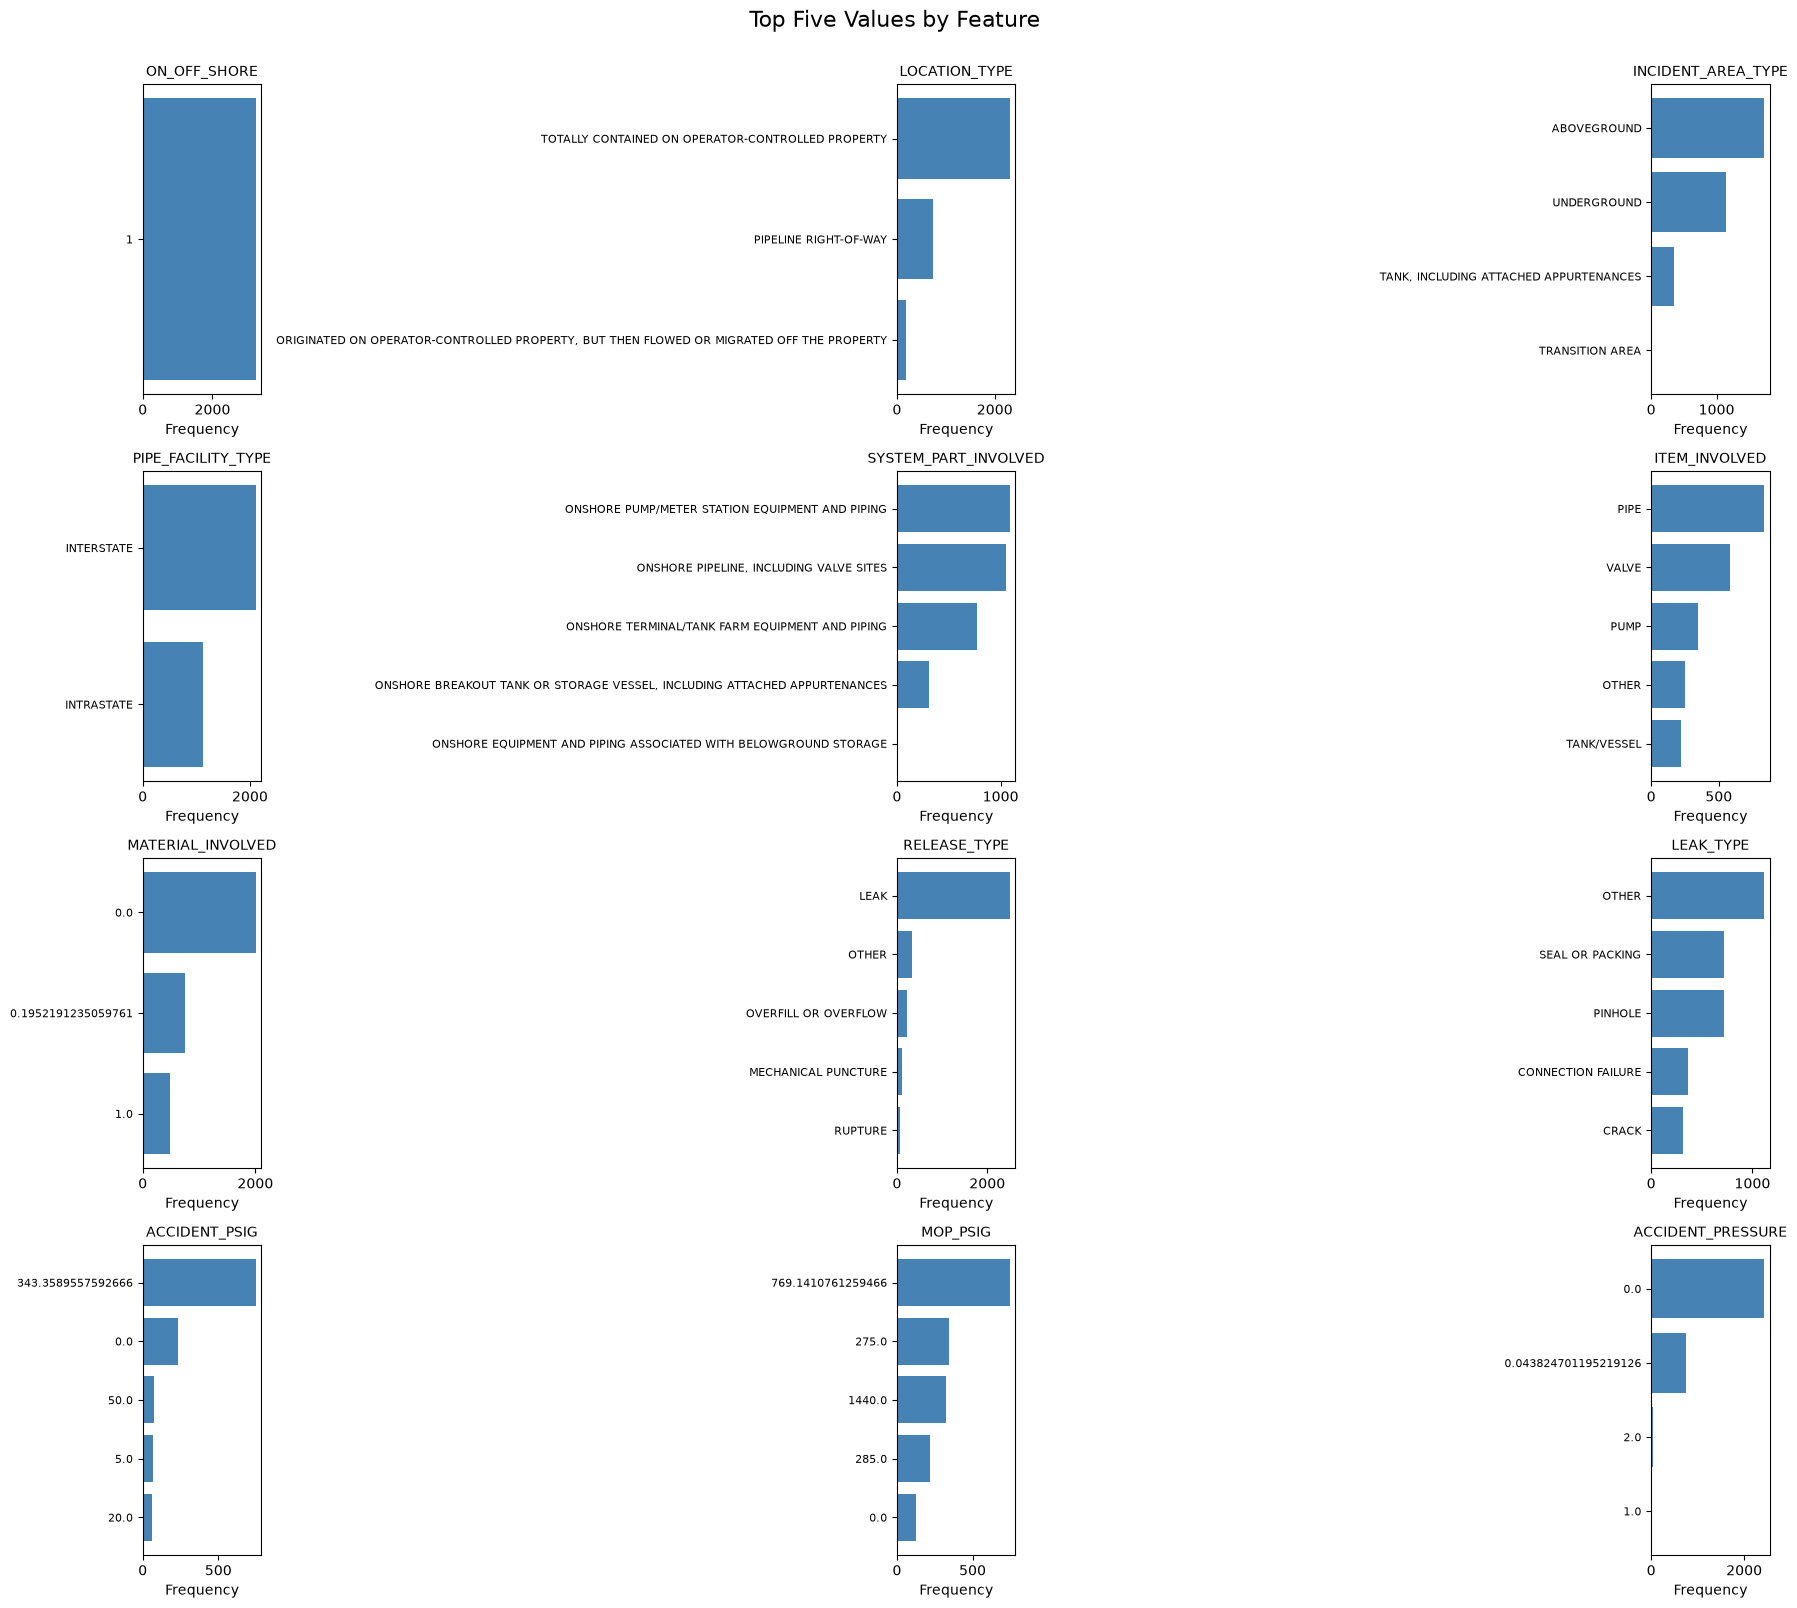

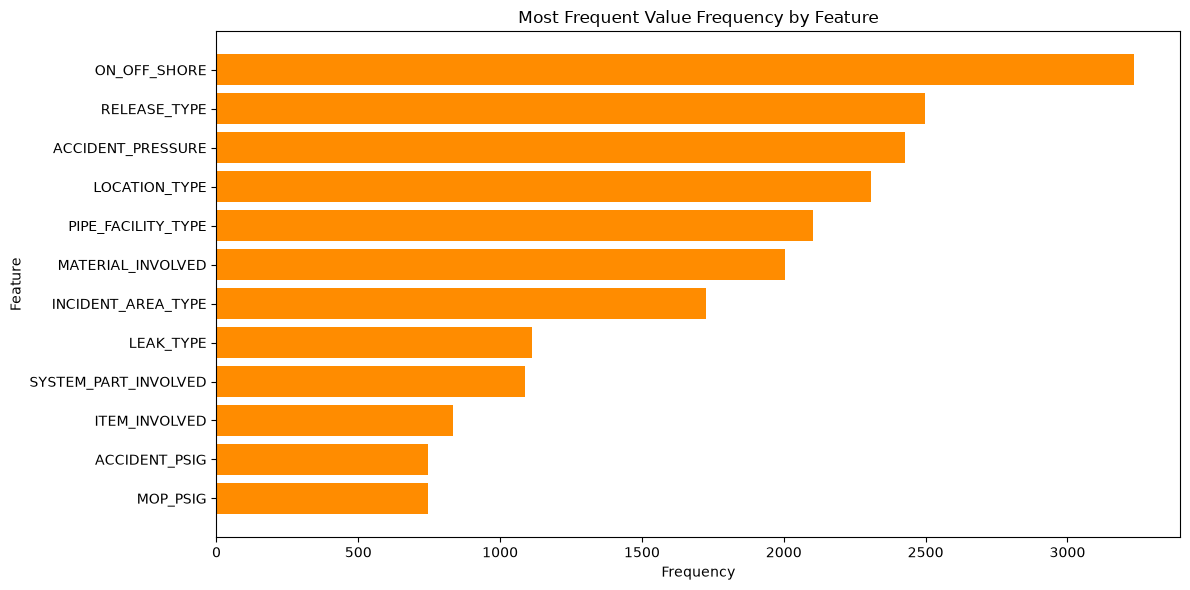

In [87]:
most_frequent_rows = []

for feature in new_df.columns:
    value_counts = new_df[feature].dropna().value_counts()

    if not value_counts.empty:
        most_frequent_rows.append({
            'feature': feature,
            'most_frequent_value': value_counts.index[0],
            'frequency': int(value_counts.iloc[0]),
            'frequency_percent': round(value_counts.iloc[0] / value_counts.sum() * 100, 2)
        })

most_frequent_df = pd.DataFrame(most_frequent_rows)
most_frequent_df = most_frequent_df.sort_values('frequency', ascending=False).reset_index(drop=True)
most_frequent_df.to_csv('most_frequent_by_feature.csv', index=False)

print('Most frequent value for each feature:')
display(most_frequent_df)
print('Exported to most_frequent_by_feature.csv')

# Compare the five most frequent values for each feature.
feature_names = new_df.columns
number_of_columns = 3
number_of_rows = int(np.ceil(len(feature_names) / number_of_columns))
fig, axes = plt.subplots(
    number_of_rows,
    number_of_columns,
    figsize=(18, number_of_rows * 4),
    squeeze=False
)
axes = axes.ravel()

for axis, feature in zip(axes, feature_names):
    top_values = new_df[feature].dropna().value_counts().head(5).sort_values()
    axis.barh(top_values.index.astype(str), top_values.values, color='steelblue')
    axis.set_title(feature, fontsize=10)
    axis.set_xlabel('Frequency')
    axis.tick_params(axis='y', labelsize=8)

for axis in axes[len(feature_names):]:
    axis.set_visible(False)

fig.suptitle('Top Five Values by Feature', fontsize=16, y=1.002)
plt.tight_layout()
fig.savefig('top_five_values_by_feature.png', dpi=150, bbox_inches='tight')
plt.show()

# Visualize the modal frequency across all features.
frequency_fig = plt.figure(figsize=(12, max(6, len(most_frequent_df) * 0.3)))
plt.barh(
    most_frequent_df['feature'],
    most_frequent_df['frequency'],
    color='darkorange'
)
plt.xlabel('Frequency')
plt.ylabel('Feature')
plt.title('Most Frequent Value Frequency by Feature')
plt.gca().invert_yaxis()
plt.tight_layout()
frequency_fig.savefig('most_frequent_frequency_by_feature.png', dpi=150, bbox_inches='tight')
plt.show()

In [113]:
from sklearn.preprocessing import OrdinalEncoder
X = new_df.to_numpy()
encoders=[]
right_indices = []
for i in range(X.shape[1]):
    if  type(X[0,i:i+1][0])==type('str'):
        encoders.append(OrdinalEncoder())
        right_indices.append(i)
        X[:,i:i+1] = encoders[-1].fit_transform(X[:,i:i+1])
X

array([[1, 2.0, 0.0, ..., 700.0, 1440.0, 0.0],
       [1, 2.0, 0.0, ..., 98.0, 275.0, 0.0],
       [1, 2.0, 0.0, ..., 22.0, 285.0, 0.0],
       ...,
       [1, 2.0, 0.0, ..., 1050.0, 1480.0, 0.0],
       [1, 2.0, 0.0, ..., 343.3589557592666, 769.1410761259466,
        0.043824701195219126],
       [1, 2.0, 0.0, ..., 731.0, 720.0, 1.0]],
      shape=(3235, 12), dtype=object)

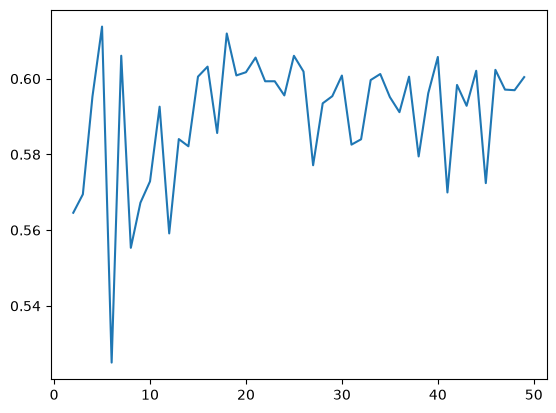

3


In [114]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
scores = []
for i in range(2,50):
    model = KMeans(n_clusters=i)
    cluster_labels = model.fit_predict(X)
    scores.append(silhouette_score(X,cluster_labels))
plt.plot(range(2,50),scores)
plt.show()
print(np.argmax(scores))

In [118]:
model = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = model.fit_predict(X)
centers = model.cluster_centers_

# Decode ordinal categorical features into their original labels.
decoded_centers = centers.astype(object)
for encoder, column_index in zip(encoders, right_indices):
    encoded_values = np.rint(centers[:, column_index]).astype(int)
    encoded_values = np.clip(encoded_values, 0, len(encoder.categories_[0]) - 1)
    decoded_centers[:, column_index] = encoder.inverse_transform(
        encoded_values.reshape(-1, 1)
    ).ravel()

cluster_centers_df = pd.DataFrame(decoded_centers, columns=new_df.columns)

# Round numeric center values to the nearest whole number.
for column in cluster_centers_df.columns:
    numeric_values = pd.to_numeric(cluster_centers_df[column], errors='coerce')
    numeric_mask = numeric_values.notna()
    cluster_centers_df.loc[numeric_mask, column] = numeric_values[numeric_mask].round().astype(int)

# Convert manually encoded fields back to their original meanings.
cluster_centers_df['ON_OFF_SHORE'] = cluster_centers_df['ON_OFF_SHORE'].map({
    0: 'OFFSHORE',
    1: 'ONSHORE'
}).fillna(cluster_centers_df['ON_OFF_SHORE'])

cluster_centers_df['PIPE_FACILITY_TYPE'] = cluster_centers_df['PIPE_FACILITY_TYPE'].map({
    0: 'INTERSTATE',
    1: 'INTRASTATE'
}).fillna(cluster_centers_df['PIPE_FACILITY_TYPE'])

cluster_centers_df['MATERIAL_INVOLVED'] = cluster_centers_df['MATERIAL_INVOLVED'].map({
    0: 'OTHER',
    1: 'CARBON STEEL'
}).fillna(cluster_centers_df['MATERIAL_INVOLVED'])

cluster_centers_df['ACCIDENT_PRESSURE'] = cluster_centers_df['ACCIDENT_PRESSURE'].map({
    0: 'PRESSURE DID NOT EXCEED MOP',
    1: 'PRESSURE EXCEEDED MOP BUT NOT 110%',
    2: 'PRESSURE EXCEEDED 110% OF MOP'
}).fillna(cluster_centers_df['ACCIDENT_PRESSURE'])

cluster_centers_df.index.name = 'cluster'
cluster_centers_df

,ON_OFF_SHORE,LOCATION_TYPE,INCIDENT_AREA_TYPE,PIPE_FACILITY_TYPE,SYSTEM_PART_INVOLVED,ITEM_INVOLVED,MATERIAL_INVOLVED,RELEASE_TYPE,LEAK_TYPE,ACCIDENT_PSIG,MOP_PSIG,ACCIDENT_PRESSURE
cluster,,,,,,,,,,,,
0,ONSHORE,TOTALLY CONTAINED ON OPERATOR-CONTROLLED PROPERTY,"TANK, INCLUDING ATTACHED APPURTENANCES",INTERSTATE,ONSHORE PUMP/METER STATION EQUIPMENT AND PIPING,RELIEF LINE,OTHER,MECHANICAL PUNCTURE,OTHER,68,227,PRESSURE DID NOT EXCEED MOP
1,ONSHORE,PIPELINE RIGHT-OF-WAY,"TANK, INCLUDING ATTACHED APPURTENANCES",INTERSTATE,"ONSHORE PIPELINE, INCLUDING VALVE SITES",REPAIR SLEEVE OR CLAMP,OTHER,MECHANICAL PUNCTURE,OTHER,996,1533,PRESSURE DID NOT EXCEED MOP
2,ONSHORE,TOTALLY CONTAINED ON OPERATOR-CONTROLLED PROPERTY,"TANK, INCLUDING ATTACHED APPURTENANCES",INTERSTATE,ONSHORE PUMP/METER STATION EQUIPMENT AND PIPING,REPAIR SLEEVE OR CLAMP,OTHER,LEAK,OTHER,317,887,PRESSURE DID NOT EXCEED MOP


In [119]:
cluster_centers_df.to_csv('centers_of_incidents',index=False)